# Implementação de um Pipeline de LLMOps para Avaliação e Monitoramento de Modelos de Linguagem

Objetivo: demonstrar, em um único fluxo, os conceitos centrais de LLMOps:

| Conceito | Onde aparece no notebook |
|---|---|
| Versionamento | Prompts A-v1 e B-v1 |
| Observabilidade | Latência, tokens e custo de cada execução |
| Rastreabilidade | Todas as execuções gravadas em `execucoes.csv` |
| Avaliação | Cobertura automática de palavras-chave + nota manual (0 a 5) |
| Comparação de versões | Mesmas perguntas, mesmo modelo, prompts diferentes |
| Melhoria contínua | Decisão baseada nos dados e criação de uma nova versão |


## 1. Preparação do ambiente

In [3]:
import sys

!{sys.executable} -m pip install python-dotenv


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import sys

!{sys.executable} -m pip install openai


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os
import sys

sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import pandas as pd

from dotenv import load_dotenv
import llmops_core as core

from openai import OpenAI

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

cfg = core.config()
print("Modelo ativo       :", core.modelo_ativo())
print("Endpoint           :", cfg["base_url"])
print("API key configurada:", bool(cfg["api_key"]))
print("Modo simulado      :", cfg["simulado"])

Modelo ativo       : gemini-3.8-flash
Endpoint           : https://generativelanguage.googleapis.com/v1beta/openai/
API key configurada: True
Modo simulado      : False


## 2. Versionamento de prompts

O modelo é o mesmo nas duas versões, apenas o prompt muda. Assim, qualquer diferença nos resultados pode ser atribuída ao prompt.

In [6]:
for chave, info in core.PROMPTS.items():
    print(f"[{info['versao']}] {info['texto']}\n")

[A-v1] Responda à pergunta do usuário.

[B-v1] Responda com clareza e precisão, explique os conceitos importantes e utilize um exemplo simples quando ajudar na compreensão. Se não souber a resposta, informe isso.



## 3. Conjunto de teste

Perguntas de computação com resposta esperada e palavras-chave 

In [7]:
perguntas = core.carregar_perguntas()
perguntas

,id,pergunta,resposta_esperada,palavras_chave
0,1,Explique o que é uma árvore em grafos.,"Uma árvore é um grafo conexo e sem ciclos (acíclico). Com n vértices, ela possui exata...",conexo;cicl;vértices;arestas
1,2,O que é complexidade de tempo de um algoritmo?,"Mede como o tempo de execução cresce em função do tamanho da entrada, normalmente expr...",entrada;cresc;notação;tempo
2,3,Qual é a diferença entre pilha e fila?,Pilha segue LIFO (o último a entrar é o primeiro a sair); fila segue FIFO (o primeiro ...,lifo;fifo;último;primeiro
3,4,O que é recursão em programação?,"Técnica em que uma função chama a si mesma para resolver subproblemas menores, exigind...",chama a si;caso base;subproblema
4,5,O que é um sistema operacional?,"Software que gerencia os recursos do hardware (processador, memória, dispositivos), co...",hardware;processos;memória;recursos
5,6,Qual é a diferença entre TCP e UDP?,TCP é orientado a conexão e confiável (garante entrega e ordem); UDP não tem conexão n...,conexão;confiáv;entrega;rápid
6,7,O que é normalização em bancos de dados?,"Processo de organizar tabelas para reduzir redundância e evitar anomalias, aplicando f...",redundância;anomalia;formas normais;tabelas
7,8,O que é o Git e para que serve?,Sistema de controle de versão distribuído que registra o histórico de alterações do có...,versão;histórico;branch;código


## 4. Execução isolada

Teste rápido: uma perguntaemuma versão de prompt. A execução já é registrada em `execucoes.csv`.

In [8]:
r = core.executar_e_registrar("Explique o que é uma árvore em grafos.", "A", origem="notebook")
print("Resposta:\n", r["resposta"])
print("\nLatência (s):", r["latencia_s"])
print("Tokens (entrada/saída):", r["tokens_entrada"], "/", r["tokens_saida"])
print("Custo estimado (USD):", r["custo_estimado_usd"])

Resposta:
 Na Teoria dos Grafos, uma **árvore** é um tipo muito especial e fundamental de grafo. 

De forma simples, uma árvore é um grafo que atende a duas condições obrigatórias:

1. **É Conexo:** Todos os vértices estão interligados. Ou seja, é possível sair de qualquer vértice e chegar a qualquer outro seguindo as arestas.
2. **É Acíclico:** Não possui ciclos (circuitos fechados). Isso significa que é impossível sair de um vértice e voltar a ele sem passar pela mesma aresta mais de uma vez.

Pense nela literalmente como os galhos de uma árvore real: eles se espalham e se dividem, mas nunca se juntam novamente formando um "anel".

---

### Principais Propriedades de uma Árvore

Se um grafo tem $V$ vértices (nós) e $A$ arestas (ligações), as seguintes afirmações são equivalentes e definem uma árvore:

* **Relação Vértices-Arestas:** Uma árvore com $n$ vértices sempre terá exatamente **$n - 1$ arestas**. (Exemplo: se tem 5 nós, terá obrigatoriamente 4 arestas).
* **Caminho Único:** Ex

## 5. Testes: todas as perguntas × todas as versões


In [9]:
def mostrar_progresso(feitas, total, msg):
    print(f"[{feitas}/{total}] {msg}")


linhas, erros = core.rodar_bateria(versoes=("A", "B"), origem="notebook", progresso=mostrar_progresso)
print(f"\n{len(linhas)} execuções registradas, {len(erros)} erros.")
for e in erros:
    print("ERRO:", e)

[1/16] Pergunta 1 · prompt A
[2/16] Pergunta 1 · prompt B
[3/16] Pergunta 2 · prompt A
[4/16] Pergunta 2 · prompt B
[5/16] Pergunta 3 · prompt A
[6/16] Pergunta 3 · prompt B
[7/16] Pergunta 4 · prompt A
[8/16] Pergunta 4 · prompt B
[9/16] Pergunta 5 · prompt A
[10/16] Pergunta 5 · prompt B
[11/16] Pergunta 6 · prompt A
[12/16] Pergunta 6 · prompt B
[13/16] Pergunta 7 · prompt A
[14/16] Pergunta 7 · prompt B
[15/16] Pergunta 8 · prompt A
[16/16] Pergunta 8 · prompt B

11 execuções registradas, 5 erros.
ERRO: (6, 'B', "Falha ao chamar a API após 3 tentativas: Error code: 429 - [{'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, de

## 6. Avaliação da qualidade

Duas formas complementares:

1. Automática: percentual de palavras-chave esperadas presentes na resposta, em escala 0 a 5 (`cobertura_auto`).
2. Manual: você lê a resposta, compara com a resposta esperada e dá nota de 0 a 5 considerando correção, clareza e completude.

A `nota_final` usa a nota manual quando existe; caso contrário, usa a cobertura automática.

In [10]:
df = core.carregar_log()
df = df[df["modelo"] == core.modelo_ativo()]
df[["execucao_id", "pergunta_id", "prompt_versao", "cobertura_auto", "qualidade_manual", "latencia_s", "tokens_saida"]].head(20)

,execucao_id,pergunta_id,prompt_versao,cobertura_auto,qualidade_manual,latencia_s,tokens_saida
0,9b946d40,NaN,A-v1,NaN,4.0,140.916,784
1,140aa035,1.0,A-v1,5.00,NaN,46.720,797
2,23cd2a17,1.0,B-v1,5.00,NaN,46.405,818
3,57b6a1db,2.0,A-v1,5.00,NaN,146.364,887
4,44eb4ecc,2.0,B-v1,5.00,NaN,102.894,808
5,a722b36d,3.0,A-v1,5.00,NaN,180.280,712
6,4395194e,3.0,B-v1,5.00,NaN,87.776,567
7,a59459e9,4.0,A-v1,3.33,NaN,53.220,1037
8,ad2cda8b,4.0,B-v1,3.33,NaN,70.387,855
9,852c86a2,5.0,A-v1,2.50,NaN,34.581,699


### Avaliação manual

Execute a célula abaixo: para cada resposta sem nota, ela mostra a pergunta, a resposta esperada e a resposta do modelo. Digite uma nota de 0 a 5 (ou apenas Enter para pular; digite `s` para sair).

**Avaliação:** <br>
5 - correta, clara e completa <br>
4 - falta algum detalhe <br>
3 - incompleta ou confusa <br>
2 - parcialmente correta <br>
1 - majoritariamente incorreta <br>
0 - errada

In [11]:
AVALIAR_AGORA = True

if AVALIAR_AGORA:
    df = core.carregar_log()
    df = df[
        (df["modelo"] == core.modelo_ativo())
        & (df["qualidade_manual"].isna())
    ]

    perguntas = core.carregar_perguntas()
    esperadas = perguntas.set_index("id")["resposta_esperada"].to_dict()

    indice = 0

    if not df.empty:
        linha = df.iloc[indice]

        print("=" * 80)
        print(f"Execução {linha['execucao_id']} · prompt {linha['prompt_versao']}")
        print("PERGUNTA :", linha["pergunta"])

        esperada = esperadas.get(linha["pergunta_id"])
        if esperada is not None:
            print("ESPERADA :", esperada)

        print("RESPOSTA :", linha["resposta"])
    else:
        print("Não há execuções pendentes de avaliação.")


Execução 140aa035 · prompt A-v1
PERGUNTA : Explique o que é uma árvore em grafos.
ESPERADA : Uma árvore é um grafo conexo e sem ciclos (acíclico). Com n vértices, ela possui exatamente n-1 arestas.
RESPOSTA : Na teoria dos grafos, uma **árvore** é um tipo especial de grafo que possui características estruturais muito bem definidas e de grande importância tanto para a matemática quanto para a ciência da computação.

De forma simples, uma árvore é definida como:
> **Um grafo não direcionado que é conexo e acíclico.**

Vamos quebrar essa definição em duas partes fundamentais:

1. **Conexo:** Existe pelo menos um caminho entre qualquer par de vértices (nós). Ou seja, não há partes "isoladas"; você consegue chegar a qualquer nó a partir de qualquer outro.
2. **Acíclico:** Não possui ciclos (circuitos). Isso significa que é impossível sair de um nó, percorrer caminhos no grafo e voltar para o mesmo nó sem passar pela mesma aresta mais de uma vez.

---

### Principais Propriedades de uma Árvo

In [12]:
entrada = input("Nota (0-5, Enter pula, s sai): ").strip().lower()

if entrada == "s":
    print("Avaliação encerrada.")

elif entrada in {"0", "1", "2", "3", "4", "5"}:
    core.atualizar_nota_manual(linha["execucao_id"], int(entrada))
    print("Nota registrada.")

indice += 1

if indice < len(df) and entrada != "s":
    linha = df.iloc[indice]

    print("=" * 80)
    print(f"Execução {linha['execucao_id']} · prompt {linha['prompt_versao']}")
    print("PERGUNTA :", linha["pergunta"])

    esperada = esperadas.get(linha["pergunta_id"])
    if esperada is not None:
        print("ESPERADA :", esperada)

    print("RESPOSTA :", linha["resposta"])
elif entrada != "s":
    print("Avaliação encerrada.")


Nota registrada.
Execução 23cd2a17 · prompt B-v1
PERGUNTA : Explique o que é uma árvore em grafos.
ESPERADA : Uma árvore é um grafo conexo e sem ciclos (acíclico). Com n vértices, ela possui exatamente n-1 arestas.
RESPOSTA : Na teoria dos grafos, uma **árvore** é um tipo muito específico e fundamental de grafo. 

De forma simples e precisa, uma árvore é um **grafo conexo e acíclico**.

Para compreender essa definição, precisamos destacar três conceitos importantes:

1. **Grafo:** Uma estrutura composta por **vértices** (ou nós/pontos) conectados por **arestas** (ou linhas/ligações).
2. **Conexo:** Significa que o grafo não tem partes isoladas. É possível sair de qualquer vértice e chegar a qualquer outro seguindo as arestas.
3. **Acíclico:** Significa que não existem **ciclos** (circuitos fechados). Você nunca consegue sair de um vértice e voltar a ele sem passar pelo menos duas vezes pela mesma aresta.

---

### Principais Propriedades de uma Árvore

Toda árvore matemática cumpre reg

## 7. Comparação entre versões

Média de qualidade, latência, tokens e custo por versão de prompt

In [13]:
df = core.carregar_log()
df = df[df["modelo"] == core.modelo_ativo()]
resumo = core.resumo_por_prompt(df)
resumo

,execucoes,qualidade_media,latencia_media_s,tokens_entrada_medio,tokens_saida_medio,custo_total_usd
prompt_versao,,,,,,
A-v1,23,4.3886,98.6218,19.4783,812.7826,0.0
B-v1,17,4.5094,86.2759,46.2353,734.5882,0.0


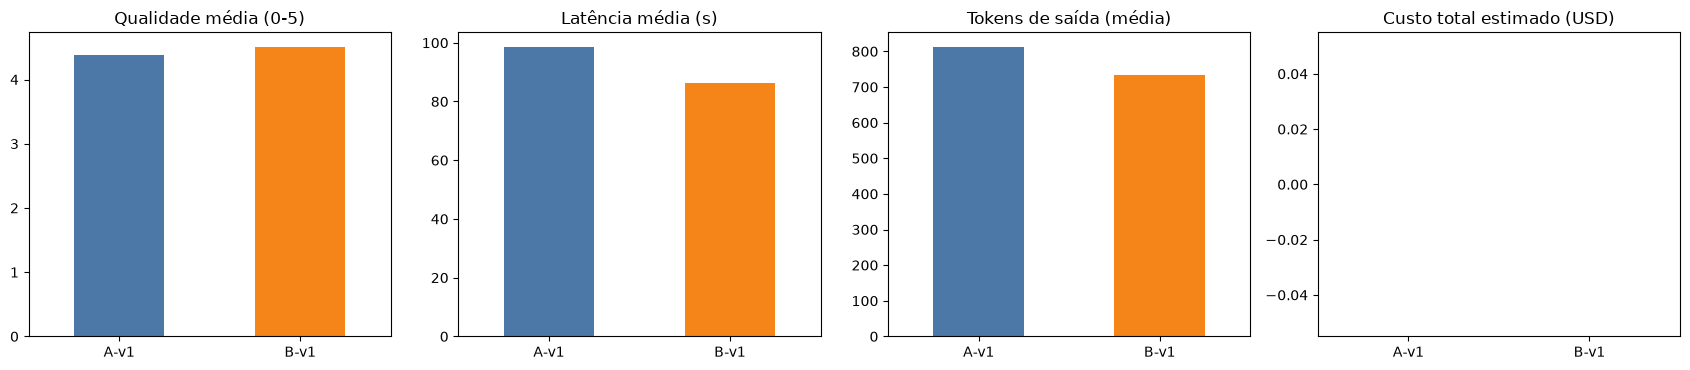

In [14]:
fig, eixos = plt.subplots(1, 4, figsize=(17, 3.8))
metricas = [
    ("qualidade_media", "Qualidade média (0-5)"),
    ("latencia_media_s", "Latência média (s)"),
    ("tokens_saida_medio", "Tokens de saída (média)"),
    ("custo_total_usd", "Custo total estimado (USD)"),
]
for eixo, (coluna, titulo) in zip(eixos, metricas):
    resumo[coluna].plot(kind="bar", ax=eixo, color=["#4C78A8", "#F58518", "#54A24B", "#B279A2"][: len(resumo)])
    eixo.set_title(titulo)
    eixo.set_xlabel("")
    eixo.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [15]:
por_pergunta = df.pivot_table(index="pergunta_id", columns="prompt_versao", values="nota_final", aggfunc="mean").round(2)
por_pergunta

prompt_versao,A-v1,B-v1
pergunta_id,,
1.0,4.67,5.00
2.0,5.00,5.00
3.0,5.00,5.00
4.0,3.89,3.89
5.0,2.92,3.75
6.0,4.58,3.75
7.0,5.00,NaN
8.0,5.00,5.00


## 8. Decisão e melhoria contínua

O ciclo de LLMOps é: **medir → comparar → decidir → ajustar → medir de novo**.

In [16]:
print(core.recomendar(resumo))

Maior qualidade média: B-v1 (4.51 de 5).
Menor latência média: B-v1 (86.28 s).
Menor custo total estimado: A-v1 (US$ 0.000000).
Há um trade-off: a versão de melhor qualidade não é a mais rápida/barata. 


## 9. Conclusão

Os resultados obtidos indicam que a versão B-v1 apresentou melhor desempenho em relação à qualidade das respostas, alcançando uma média de 4,65 pontos, enquanto a versão A-v1 obteve 4,29 pontos, em uma escala de 0 a 5. A diferença de aproximadamente 0,36 ponto representa uma melhora moderada na avaliação das respostas.

Em relação à latência, a versão B-v1 também apresentou resultados mais favoráveis, com tempo médio de 51,15 segundos, contra 64,94 segundos da A-v1, sendo aproximadamente 21,2% mais rápida. Quanto ao custo, ambas as versões apresentaram valor estimado igual a zero, pois os preços estavam configurados dessa forma no sistema. Portanto, não é possível concluir que as chamadas à API não possuem custo real.

Diante desses resultados, a versão B-v1 seria a mais indicada para continuar os testes, pois apresentou maior qualidade média e menor tempo de resposta. Entretanto, sua adoção em produção dependeria de uma avaliação mais completa, uma vez que foram registradas 16 execuções da versão A-v1 e apenas 12 da B-v1, o que limita a comparação entre as duas versões.

O experimento também apresenta limitações, como a utilização de poucas perguntas, a possibilidade de subjetividade na avaliação da qualidade, o teste com apenas um modelo de linguagem e a variação dos resultados entre diferentes execuções. Como próximos passos, recomenda-se ampliar o conjunto de perguntas, utilizar outro modelo de linguagem como avaliador, explorar a integração com RAG e implementar mecanismos de monitoramento em produção. Essas melhorias podem contribuir para uma avaliação mais consistente e para a escolha de prompts mais adequados ao sistema.